In [1]:
#Import Libraries
import numpy as np
import pandas as pd
import keras
import cv2
from matplotlib import pyplot as plt
import os
import random
from PIL import Image

In [2]:
df = pd.read_csv("train.csv")
base_path = "./images/"

In [3]:
df

,id,url,landmark_id
0,6e158a47eb2ca3f6,https://upload.wikimedia.org/wikipedia/commons...,142820
1,202cd79556f30760,http://upload.wikimedia.org/wikipedia/commons/...,104169
2,3ad87684c99c06e1,http://upload.wikimedia.org/wikipedia/commons/...,37914
3,e7f70e9c61e66af3,https://upload.wikimedia.org/wikipedia/commons...,102140
4,4072182eddd0100e,https://upload.wikimedia.org/wikipedia/commons...,2474
...,...,...,...
4132909,fc0f007893b11ba7,https://upload.wikimedia.org/wikipedia/commons...,172138
4132910,39aad18585867916,https://upload.wikimedia.org/wikipedia/commons...,162860
4132911,fd0725460e4ebbec,https://upload.wikimedia.org/wikipedia/commons...,191243
4132912,73691ae29e24ba19,https://upload.wikimedia.org/wikipedia/commons...,145760


In [4]:
samples = 20000

import glob
import os

available = {
    os.path.splitext(os.path.basename(f))[0]
    for f in glob.glob("images/**/*.jpg", recursive=True)
}

df = df[df["id"].isin(available)]

num_classes = len(df["landmark_id"].unique())
num_data = len(df)

In [5]:
num_classes

7444

In [6]:
num_data

8266

In [7]:
data = pd.DataFrame(df["landmark_id"].value_counts())

data.reset_index(inplace=True)
data.head()

,landmark_id,count
0,138982,25
1,62798,11
2,83144,8
3,171772,8
4,45428,7


In [8]:
data.tail()

,landmark_id,count
7439,64044,1
7440,201304,1
7441,141926,1
7442,165070,1
7443,193078,1


In [9]:
data.columns = ['landmark_id', 'count']

In [10]:
data['count'].describe()

count    7444.000000
mean        1.110425
std         0.502744
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        25.000000
Name: count, dtype: float64

(array([0.000e+00, 0.000e+00, 6.819e+03, 0.000e+00, 5.120e+02, 0.000e+00,
        7.600e+01, 0.000e+00, 2.500e+01, 0.000e+00, 6.000e+00, 0.000e+00,
        1.000e+00, 0.000e+00, 1.000e+00, 0.000e+00, 2.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+0

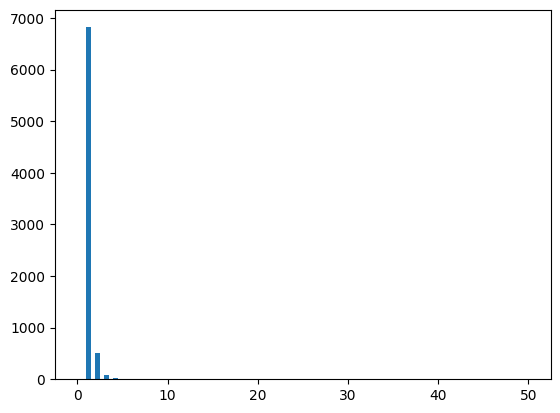

In [11]:
plt.hist(data['count'], 100, range=(0,50), label='test')

In [12]:
data['landmark_id'].describe()

count      7444.000000
mean     101607.311257
std       58944.943483
min           0.000000
25%       49930.250000
50%      101024.000000
75%      153596.250000
max      203073.000000
Name: landmark_id, dtype: float64

In [13]:
data.columns = ['landmark_id', 'count']

(array([7.442e+03, 1.000e+00, 1.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00, 0.000e+00,
        0.000e+00, 0.000e+00, 0.000e+0

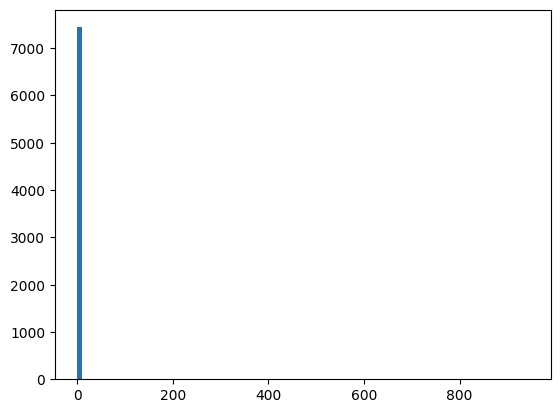

In [14]:
plt.hist(data['count'], 100, range=(0,944), label='test')

In [15]:
data['count'].between(0,5).sum()

7438

In [16]:
data['count'].between(5,10).sum()

10

(array([1., 0., 0., ..., 1., 1., 2.]),
 array([0.00000000e+00, 2.72800913e+01, 5.45601827e+01, ...,
        2.03018440e+05, 2.03045720e+05, 2.03073000e+05]),
 <BarContainer object of 7444 artists>)

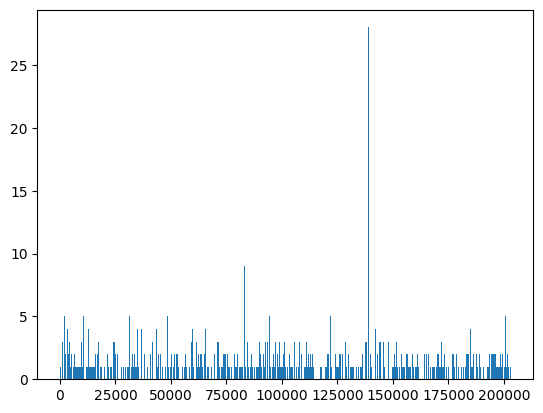

In [17]:
plt.hist(df["landmark_id"], bins=df["landmark_id"].nunique())

In [18]:
# Training of Model
from sklearn.preprocessing import LabelEncoder

lencoder = LabelEncoder()
lencoder.fit(df["landmark_id"])

LabelEncoder()

In [19]:
df.head()

,id,url,landmark_id
108,0036d78c05c194d9,https://upload.wikimedia.org/wikipedia/commons...,50089
1262,001cd787f1e9a803,https://upload.wikimedia.org/wikipedia/commons...,61937
1567,00429b0a692bc6ec,https://upload.wikimedia.org/wikipedia/commons...,183170
2222,0082fd4214b3c2c7,https://upload.wikimedia.org/wikipedia/commons...,36407
3219,002b386016930458,https://upload.wikimedia.org/wikipedia/commons...,119649


In [20]:
def encode_label(lbl):
    return lencoder.transform(lbl)

In [21]:
def decode_label(lbl):
    return lencoder.inverse_transform(lbl)

In [22]:
def get_image_from_number(num, df):
    fname = str(df.iloc[num]["id"])
    label = df.iloc[num]["landmark_id"]

    fname = fname + ".jpg"

    f1 = fname[0]
    f3 = fname[2]

    path = os.path.join(base_path, f1, f3, fname)
    im = cv2.imread(path)

    return im, label

4 Sample images from random classes


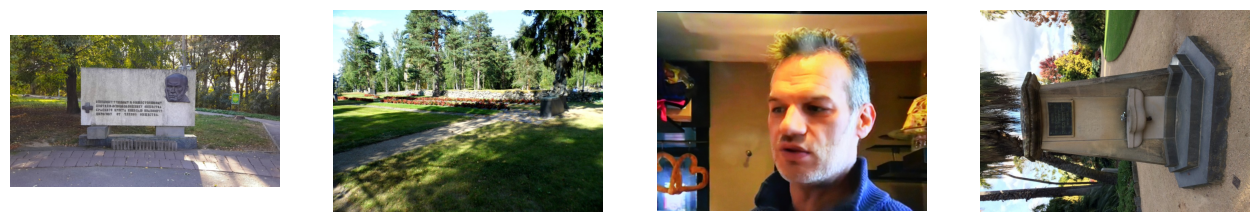

In [23]:
print("4 Sample images from random classes")

fig = plt.figure(figsize=(16,16))

for i in range(1,5):
    ri = random.choice(os.listdir(os.path.join(base_path, "0")))
    folder = os.path.join(base_path, "0", ri)

    random_img = random.choice(os.listdir(folder))
    img = np.array(Image.open(os.path.join(folder, random_img)))

    fig.add_subplot(1,4,i)
    plt.imshow(img)
    plt.axis('off')

plt.show()

In [24]:
from keras.applications.vgg19 import VGG19
from keras.layers import *
from keras import Sequential
import tensorflow as tf
tf.compat.v1.disable_eager_execution()

In [25]:
# Parameters
learning_rate = 0.0001
decay_speed = 1e-6
momentum = 0.09

loss_function = "sparse_categorical_crossentropy"

source_model = VGG19(weights=None)

drop_layer = Dropout(0.5)
drop_layer2 = Dropout(0.5)

model = Sequential()

for layer in source_model.layers[:-1]:
    if layer == source_model.layers[-25]:
        model.add(BatchNormalization())
    model.add(layer)

model.add(Dense(num_classes, activation="softmax"))

model.summary()

Instructions for updating:
Colocations handled automatically by placer.
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 batch_normalization (BatchN  (None, 224, 224, 3)      12        
 ormalization)                                                   
                                                                 
 block1_conv1 (Conv2D)       (None, 224, 224, 64)      1792      
                                                                 
 block1_conv2 (Conv2D)       (None, 224, 224, 64)      36928     
                                                                 
 block1_pool (MaxPooling2D)  (None, 112, 112, 64)      0         
                                                                 
 block2_conv1 (Conv2D)       (None, 112, 112, 128)     73856     
                                                                 
 block2_conv2 (Conv2D)       (None, 112, 112, 128)

In [26]:
optim = tf.keras.optimizers.RMSprop(learning_rate=learning_rate)

model.compile(
    optimizer=optim,
    loss=loss_function,
    metrics=["accuracy"]
)

In [27]:
def image_reshape(im, target_size):
    return cv2.resize(im, target_size)

In [28]:
def image_reshape(im, target_size):
    return cv2.resize(im, target_size)


def get_batch(dataframe, start, batch_size):
    image_array = []
    label_array = []

    end_img = start + batch_size
    if(end_img > len(dataframe)):
        end_img = len(dataframe)

    for idx in range(start, end_img):
        n = idx
        im, label = get_image_from_number(n, dataframe)
        im = image_reshape(im, (224, 224)) / 255.0
        image_array.append(im)
        label_array.append(label)

    label_array = encode_label(label_array)

    return np.array(image_array), np.array(label_array)

In [29]:
batch_size = 16
epoch_shuffle = True
weight_classes = True
epochs = 1

# split
train, val = np.split(df.sample(frac=1), [int(0.8 * len(df))])

print(len(train))
print(len(val))

6612
1654


C:\Users\Hajira Sineen\tf210\lib\site-packages\numpy\core\fromnumeric.py:59: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


In [30]:
for e in range(epochs):
    print("Epoch :", str(e + 1) + "/" + str(epochs))

    if epoch_shuffle:
        train = train.sample(frac=1)

    for it in range(int(np.ceil(len(train) / batch_size))):
        X_train, y_train = get_batch(train, it * batch_size, batch_size)

        model.train_on_batch(X_train, y_train)

model.save("Model")

Epoch : 1/1


INFO:tensorflow:Assets written to: Model\assets


INFO:tensorflow:Assets written to: Model\assets


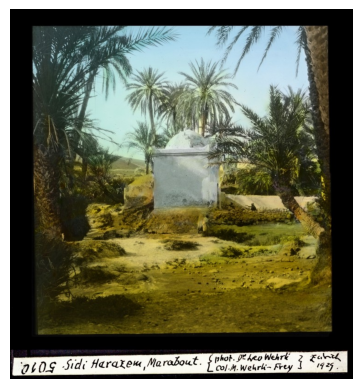

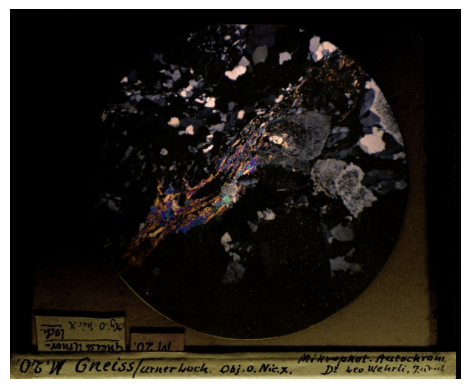

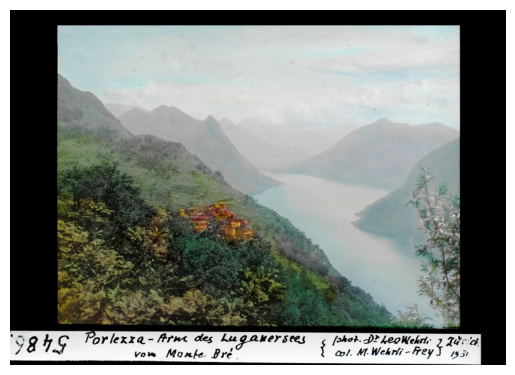

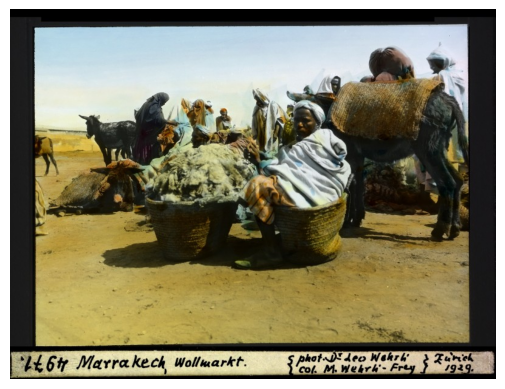

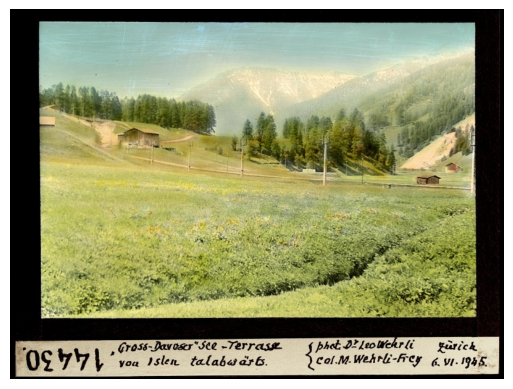

In [33]:
# Test
batch_size = 16

errors = 0
good_preds = []
bad_pred = []

for it in range(int(np.ceil(len(val)/batch_size))):
    X_val, y_val = get_batch(val, it*batch_size, batch_size)

    result = model.predict(X_val)
    cla = np.argmax(result, axis=1)

    for idx, res in enumerate(result):
        if cla[idx] != y_val[idx]:
            errors = errors + 1
            bad_pred.append([batch_size*it + idx, cla[idx], res[cla[idx]]])
        else:
            good_preds.append([batch_size*it + idx, cla[idx], res[cla[idx]]])

for i in range(min(5, len(good_preds))):
    n = int(good_preds[i][0])
    img, lbl = get_image_from_number(n, val)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    plt.imshow(img)
    plt.axis("off")
    plt.show()